> **Aktualizace, 24. října.** Nasazený model je nyní model s měřeními dělenými proudem plazmatu (`analysis/clean_model.py`, `results/clean-model.md`). Tento notebook analyzuje `cand`, předchozí nasazený model: kde se píše „nasazený“, myslí se `cand` a čísla jsou čísla `cand`. Dnešní nasazený model se hodnotí v oddílu „Nasazený model dnes“ v notebooku 09. Čas dnešního nasazeného modelu přes `predict.py` (jen numpy, jedno jádro CPU AMD Ryzen 5 7535HS, změřeno po posledním exportu, 3 000 volání po jednom řádku): medián 0,065 ms, 99. percentil 0,165 ms, nejhorší volání 0,28 ms; v dávkách po 2048 řádcích asi 230 000 odhadů za sekundu. Tabulky níže jsou dřívější měření předchozího modelu na strojích, které jmenují.

# 05 Odezva v reálném čase: je síť dost rychlá pro řízení plazmatu?

**Otázka (REQ-002).** Zadání chce reakci v jednotkách až desítkách milisekund, GPU je povolena. Jak dlouho trvá jeden odhad základní sítě (24 vstupů, 107 152 parametrů), jak velké jsou vzácné pomalé odlehlé hodnoty a mění se odpověď podle toho,
jak se síť pustí (PyTorch na CPU, čisté numpy, GPU od Applu, dávky)?

`analysis/latency.py` to jednou změřil a uložil `out/latency.json`. Tady ta čísla ukážeme, **změříme znovu**
s menším počtem opakování v tomto běhu (stroj sdílí s jinými úlohami, takže chvost je nepřesný), ověříme, že kopie v numpy dává
stejný výstup, a ověříme, že natrénované váhy dobu nemění.

Rozsah: měří se čas dopředného průchodu modelu (a standardizace kolem něj). Nezahrnuje čtení
senzorů, přenos dat do řadiče ani samotný řídicí algoritmus. Nasazený model (46 vstupů, ridge pro proud plazmatu, síť pro limiter spouštěná podmínkou) je změřený v `results/latency-shipped.md` (čte se v oddílu 1b níže) a v notebooku 09; síť s časovým kontextem o 72 vstupech změřená nebyla.

Doba běhu: asi 10 s (2 vlákna CPU); potřebuje surová data a `out/latency.json` (vytvoří ho `analysis/run_analyses.py`).

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data: HACKATHON_HOME, jinak samotný repozitář, pokud má složku data/, jinak nadřazená složka repozitáře.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "analysis" / "common.py").exists()), None)
if repo is None:
    raise SystemExit("Spusťte z vnitřku repozitáře")
os.environ.setdefault("HACKATHON_HOME", str(repo if (repo / "data").is_dir() else repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("složka se surovými daty nalezena:", C.DATA.exists(), "| složka s výsledky nalezena:", C.OUT.exists())

složka se surovými daty nalezena: True | složka s výsledky nalezena: True


## 1. Uložené měření

In [2]:
lat = json.load(open(C.OUT / "latency.json"))
KEY = {"saved_parameters": lat["parameters"]}
KEY["load_average_1min_at_start"] = round(os.getloadavg()[0], 1)  # jiné úlohy na stroji nafukují chvost nového měření
KEY["cpu_cores"] = os.cpu_count()
print(f"zátěž stroje (průměr za 1 min) při startu notebooku: {KEY['load_average_1min_at_start']} na {KEY['cpu_cores']} jádrech")
print("CPU uloženého běhu:", lat.get("cpu"), "| PyTorch", torch.__version__, "| zátěž uloženého běhu (1, 5, 15 min):", lat.get("load_average_start"))
rows = [dict(setting=k, median_ms=v["median_ms"], p99_ms=v["p99_ms"], p999_ms=v["p999_ms"], max_ms=v["max_ms"]) for k, v in lat.items() if isinstance(v, dict)]
saved_tab = pd.DataFrame(rows).set_index("setting")
print(f"síť s {lat['parameters']:,} parametry, 24 vstupy, 16 výstupy; časy v milisekundách (uložený běh, jedno vlákno {lat.get('cpu', 'neznámého CPU')}, sdílený stroj)")
print(saved_tab.round(4).to_string())
KEY["saved"] = {k: {m: round(float(x), 4) for m, x in v.items()} for k, v in lat.items() if isinstance(v, dict) and k in ("cpu_1_thread_single_sample", "numpy_single_sample", "mps_single_sample", "mps_batch_4096", "cpu_batch_4096")}

zátěž stroje (průměr za 1 min) při startu notebooku: 1.2 na 12 jádrech
CPU uloženého běhu: x86_64 | PyTorch 2.14.1+cu130 | zátěž uloženého běhu (1, 5, 15 min): [4.89, 2.68, 2.48]
síť s 107,152 parametry, 24 vstupy, 16 výstupy; časy v milisekundách (uložený běh, jedno vlákno x86_64, sdílený stroj)
                            median_ms  p99_ms  p999_ms  max_ms
setting                                                       
cpu_1_thread_single_sample     0.0354  0.0457   0.0651  0.1140
cpu_4_thread_single_sample     0.0356  0.0437   0.0528  0.0771
cpu_batch_64                   0.1162  0.1343   0.1514  0.1561
cpu_batch_1024                 0.9112  0.9516   1.2595  1.2725
cpu_batch_4096                 5.4056  5.8127   6.0474  6.0912
numpy_single_sample            0.0210  0.0261   0.0320  0.0396
cpu_end_to_end_numpy           0.0243  0.0287   0.0346  0.0698


## 1b. Nasazený model, načtený z `results/latency-shipped.md`

Model, který používá prohlížeč a přednáška (obecná síť, ridge pro proud plazmatu a síť pro limiter spouštěná podle `is_limited`), měřil vlastní skript; jeho čísla se čtou z toho souboru s výsledky, nejsou opsaná ručně.

In [3]:
import re
ship = {}
for line in (repo / "results" / "latency-shipped.md").read_text().splitlines():
    m = re.match(r"^\| (\S+) \| ([\d.]+) \| ([\d.]+) \| ([\d.]+) \| ([\d.]+) \|", line)
    if m:
        ship[m.group(1)] = dict(median_ms=float(m.group(2)), p99_ms=float(m.group(3)), p999_ms=float(m.group(4)), max_ms=float(m.group(5)))
ship_tab = pd.DataFrame(ship).T
print("nasazený model, jeden vzorek, milisekundy (Apple M5, jedno jádro CPU, stroj nebyl v klidu: viz soubor s výsledky)")
print(ship_tab.round(4).to_string())
KEY["shipped"] = {k: v for k, v in ship.items() if k.startswith("numpy_end_to_end")}

nasazený model, jeden vzorek, milisekundy (Apple M5, jedno jádro CPU, stroj nebyl v klidu: viz soubor s výsledky)
                                       median_ms  p99_ms  p999_ms  max_ms
torch_1_thread_general_net_only           0.0143  0.0561   0.1123   0.134
torch_1_thread_both_nets                  0.0290  0.1134   0.1985   0.600
torch_4_thread_general_net_only           0.0145  0.0691   0.1119   0.171
torch_4_thread_both_nets                  0.0285  0.0878   0.1552   0.244
numpy_end_to_end_diverted                 0.0154  0.0571   0.0880   0.113
numpy_end_to_end_limited                  0.0274  0.0930   0.1506   0.196
ipp1_final_predict_diverted               0.0260  0.0650   0.1048   0.196
ipp1_final_predict_limited                0.0544  0.1883   0.3108   0.341
mps_end_to_end_limited_with_transfers     0.9837  2.4127   3.1679   3.296


## 2. Změřit znovu

In [4]:
def timeit(fn, n=3000, warm=300):
    for _ in range(warm):
        fn()
    ts = np.empty(n)
    for i in range(n):
        a = time.perf_counter()
        fn()
        ts[i] = (time.perf_counter() - a) * 1000
    return ts


def stats(ts):
    return {"median_ms": float(np.median(ts)), "p99_ms": float(np.percentile(ts, 99)), "p999_ms": float(np.percentile(ts, 99.9)), "max_ms": float(ts.max())}


torch.manual_seed(0)
net = C.Net(24, 16).eval()
x1 = torch.randn(1, 24)
fresh, samples = {}, {}
with torch.no_grad():
    for threads in (1, 2):
        torch.set_num_threads(threads)
        samples[f"cpu_{threads}_thread_single_sample"] = timeit(lambda: net(x1))
    torch.set_num_threads(2)
    for b in (16, 64, 256, 1024, 4096):
        xb = torch.randn(b, 24)
        samples[f"cpu_batch_{b}"] = timeit(lambda: net(xb), n=400, warm=40)
    # týž dopředný průchod v čistém numpy: v řídicí smyčce není potřeba žádný framework pro hluboké učení
    Ws = [(m.weight.detach().numpy().T.copy(), m.bias.detach().numpy().copy()) for m in net.layers if isinstance(m, torch.nn.Linear)]
    xn = x1.numpy()

    def numpy_forward(x):
        h = x
        for i, (w, b_) in enumerate(Ws):
            h = h @ w + b_
            if i < len(Ws) - 1:
                h = h * (1.0 / (1.0 + np.exp(-h)))  # SiLU
        return h

    KEY["numpy_vs_torch_max_abs_diff"] = float(np.abs(numpy_forward(xn) - net(x1).numpy()).max())
    samples["numpy_single_sample"] = timeit(lambda: numpy_forward(xn))
    KEY["mps_available"] = bool(torch.backends.mps.is_available())
    if KEY["mps_available"]:
        try:
            dev = torch.device("mps")
            netm = C.Net(24, 16).to(dev).eval()
            xm = torch.randn(1, 24, device=dev)

            def mps_single():
                netm(xm)
                torch.mps.synchronize()
            samples["mps_single_sample"] = timeit(mps_single, n=1000, warm=100)
            xbm = torch.randn(4096, 24, device=dev)

            def mps_batch():
                netm(xbm)
                torch.mps.synchronize()
            samples["mps_batch_4096"] = timeit(mps_batch, n=200, warm=30)
        except Exception as exc:  # GPU může být vytížená nebo chybět
            print("měření GPU přeskočeno:", exc)
fresh = {k: stats(v) for k, v in samples.items()}
fresh_tab = pd.DataFrame(fresh).T
print("nové měření v tomto notebooku, milisekundy")
print(fresh_tab.round(4).to_string())
print("\nmax |numpy - torch| výstupu:", KEY["numpy_vs_torch_max_abs_diff"])
KEY["fresh"] = {k: {m: round(x, 4) for m, x in v.items()} for k, v in fresh.items()}

nové měření v tomto notebooku, milisekundy
                            median_ms  p99_ms  p999_ms   max_ms
cpu_1_thread_single_sample     0.0324  0.0536   0.0610   0.0648
cpu_2_thread_single_sample     0.0354  0.0506   0.0649   0.0944
cpu_batch_16                   0.0703  0.1156   0.1201   0.1217
cpu_batch_64                   0.1356  0.1759   0.2034   0.2054
cpu_batch_256                  0.3362  0.3842   0.3976   0.3994
cpu_batch_1024                 1.1400  1.2356   1.6967   1.8927
cpu_batch_4096                 7.6417  9.4917  12.6173  13.4330
numpy_single_sample            0.0198  0.0273   0.0375   0.0488

max |numpy - torch| výstupu: 1.4901161193847656e-08


## 3. Realistické volání: standardizovat, odhadnout, převést zpět (natrénované váhy)

`fit_mlp` vrací funkci `predict`, která standardizuje vstupy, spustí síť a přeškáluje výstupy. Učíme jednu
epochu na celé sadě (stačí na to, aby se váhy odlepily od náhodného startu; na shodě s referencí tu nezáleží) a měříme
toto volání pro jeden vzorek vedle neučené sítě.

In [5]:
df, X, Y, G, M = C.load()
torch.set_num_threads(2)
t0 = time.time()
predict, tnet, _ = C.fit_mlp(X, Y, M, epochs=1, seed=0)
print(f"učení jedné epochy trvalo {time.time() - t0:.1f} s")
x_one = X[:1].copy()
with torch.no_grad():
    s_trained = timeit(lambda: tnet(torch.zeros(1, 24)), n=3000)
    s_untrained = timeit(lambda: net(torch.zeros(1, 24)), n=3000)
s_predict = timeit(lambda: predict(x_one), n=3000)
cmp = pd.DataFrame({"natrénovaná síť, jen dopředný průchod": stats(s_trained), "neučená síť, jen dopředný průchod": stats(s_untrained), "predict(): standardizace + průchod + přeškálování": stats(s_predict)}).T
print(cmp.round(4).to_string())
KEY["trained_vs_untrained_median_ms"] = [round(stats(s_trained)["median_ms"], 4), round(stats(s_untrained)["median_ms"], 4)]
KEY["predict_call"] = {k: round(v, 4) for k, v in stats(s_predict).items()}

učení jedné epochy trvalo 1.2 s


                                                   median_ms  p99_ms  p999_ms  max_ms
natrénovaná síť, jen dopředný průchod                 0.0360  0.0479   0.0555  0.0614
neučená síť, jen dopředný průchod                     0.0358  0.0486   0.0557  0.4128
predict(): standardizace + průchod + přeškálování     0.0525  0.0914   0.1482  0.1887


## 4. Velikost dávky: odezva proti propustnosti

In [6]:
bs = [1, 16, 64, 256, 1024, 4096]
med = [fresh["cpu_2_thread_single_sample"]["median_ms"]] + [fresh[f"cpu_batch_{b}"]["median_ms"] for b in bs[1:]]
thr = [b / (m / 1000) for b, m in zip(bs, med)]
bt = pd.DataFrame({"batch": bs, "median_ms": med, "samples_per_second": thr, "microseconds_per_sample": [m * 1000 / b for m, b in zip(med, bs)]}).set_index("batch")
print(bt.round(3).to_string())
KEY["batch"] = {str(b): {"median_ms": round(m, 4), "samples_per_s": round(t)} for b, m, t in zip(bs, med, thr)}

       median_ms  samples_per_second  microseconds_per_sample
batch                                                        
1          0.035           28267.755                   35.376
16         0.070          227717.493                    4.391
64         0.136          472026.882                    2.119
256        0.336          761501.348                    1.313
1024       1.140          898257.040                    1.113
4096       7.642          536005.719                    1.866


## 5. Rezerva vůči časovému rozpočtu

                            worst_seen_ms  p999_ms  headroom_vs_1ms_(on p99.9)  headroom_vs_10ms_(on p99.9)  headroom_vs_50ms_(on p99.9)
setting                                                                                                                                 
CPU 1 vlákno, jeden vzorek            0.1      0.1                        16.4                        163.8                        819.2
numpy, jeden vzorek                   0.0      0.0                        26.6                        266.4                       1332.2
CPU, dávka 4096                      13.4     12.6                         0.1                          0.8                          4.0

proti klasickému výpočtu trvajícímu aspoň minutu je medián CPU pro jeden vzorek asi 1,853,511krát rychlejší


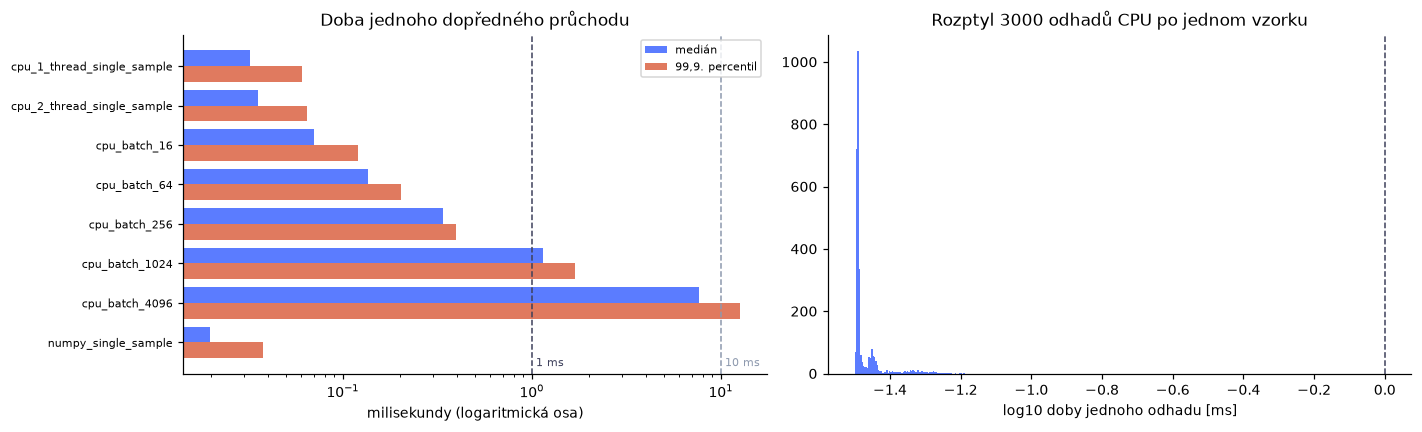

In [7]:
budgets = [1.0, 10.0, 50.0]
focus = {"CPU 1 vlákno, jeden vzorek": "cpu_1_thread_single_sample", "numpy, jeden vzorek": "numpy_single_sample", "CPU, dávka 4096": "cpu_batch_4096"}
if "mps_single_sample" in fresh:
    focus["GPU Apple, jeden vzorek"] = "mps_single_sample"
rows = []
for label, k in focus.items():
    r = {"setting": label, "worst_seen_ms": fresh[k]["max_ms"], "p999_ms": fresh[k]["p999_ms"]}
    for b in budgets:
        r[f"headroom_vs_{b:g}ms_(on p99.9)"] = b / fresh[k]["p999_ms"]
    rows.append(r)
head = pd.DataFrame(rows).set_index("setting")
print(head.round(1).to_string())
KEY["headroom_vs_1ms_on_p999"] = {l: round(1.0 / fresh[k]["p999_ms"], 1) for l, k in focus.items()}
# klasická rekonstrukce trvá minuty (text zadání); i pro dolní odhad jedné minuty vychází poměr:
KEY["speedup_vs_one_minute_on_median_cpu_1_thread"] = round(60_000 / fresh["cpu_1_thread_single_sample"]["median_ms"])
KEY["speedup_vs_one_minute_on_saved_median_cpu_1_thread"] = round(60_000 / lat["cpu_1_thread_single_sample"]["median_ms"])
print(f"\nproti klasickému výpočtu trvajícímu aspoň minutu je medián CPU pro jeden vzorek asi {KEY['speedup_vs_one_minute_on_median_cpu_1_thread']:,}krát rychlejší")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = list(fresh)
yy = np.arange(len(names))
ax[0].barh(yy - 0.2, [fresh[n]["median_ms"] for n in names], 0.4, color="#5b7cff", label="medián")
ax[0].barh(yy + 0.2, [fresh[n]["p999_ms"] for n in names], 0.4, color="#e07a5f", label="99,9. percentil")
for b, c in ((1, "#3d405b"), (10, "#8d99ae")):
    ax[0].axvline(b, color=c, ls="--", lw=1); ax[0].text(b, len(names) - 0.4, f" {b} ms", fontsize=7, color=c)
ax[0].set_xscale("log"); ax[0].set_yticks(yy); ax[0].set_yticklabels(names, fontsize=7); ax[0].invert_yaxis()
ax[0].set_xlabel("milisekundy (logaritmická osa)"); ax[0].legend(fontsize=7); ax[0].set_title("Doba jednoho dopředného průchodu")
ax[1].hist(np.log10(samples["cpu_1_thread_single_sample"]), bins=80, color="#5b7cff")
ax[1].set_xlabel("log10 doby jednoho odhadu [ms]"); ax[1].set_title("Rozptyl 3000 odhadů CPU po jednom vzorku")
ax[1].axvline(np.log10(1.0), color="#3d405b", ls="--", lw=1)
fig.tight_layout(); plt.show()

In [8]:
from IPython.display import Markdown, display
import re
def cz(text):
    """České číslování v generovaném textu: desetinná čárka místo tečky, mezera jako oddělovač tisíců."""
    text = re.sub(r"(?<![\d,.])([1-9]\d{0,2}),(\d{3})\b", "\\1\u00a0\\2", text)
    return re.sub(r"(?<=\d)\.(?=\d)", ",", text)
fc = fresh["cpu_1_thread_single_sample"]
r10 = 10.0 / fc["p999_ms"]
display(Markdown(cz(f"Proti 1 ms je 99,9. percentil tohoto běhu ({fc['p999_ms']:.1f} ms) {'v rozpočtu' if fc['p999_ms'] <= 1 else 'mimo rozpočet'}; medián ({fc['median_ms']:.4f} ms) je {'v rozpočtu' if fc['median_ms'] <= 1 else 'mimo rozpočet'}. Proti 10 ms je 99,9. percentil {'v rozpočtu s rezervou ' + format(r10, '.1f') + 'krát' if r10 >= 1 else 'mimo rozpočet'}. Tvrzení o rozpočtu se týká jen tohoto výpočtu.")))

Proti 1 ms je 99,9. percentil tohoto běhu (0,1 ms) v rozpočtu; medián (0,0324 ms) je v rozpočtu. Proti 10 ms je 99,9. percentil v rozpočtu s rezervou 163,8krát. Tvrzení o rozpočtu se týká jen tohoto výpočtu.

In [9]:
from IPython.display import Markdown, display
s1, f1 = lat["cpu_1_thread_single_sample"], fresh["cpu_1_thread_single_sample"]
sn, fn = lat["numpy_single_sample"], fresh["numpy_single_sample"]
sb, fb = lat["cpu_batch_4096"], fresh["cpu_batch_4096"]
have_gpu = all(k in d for d in (lat, fresh) for k in ("mps_single_sample", "mps_batch_4096"))   # mají ho jen běhy na GPU od Applu
gpu_line = ""
if have_gpu:
    sg, fg = lat["mps_single_sample"], fresh["mps_single_sample"]
    gb, fgb = lat["mps_batch_4096"], fresh["mps_batch_4096"]
    gpu_line = f"""- **GPU od Applu pro jeden vzorek nepomáhá.** Medián je {sg['median_ms']:.2f} ms (uloženo) a {fg['median_ms']:.2f} ms (tady), pomalejší než CPU, pravděpodobně proto, že spuštění úlohy na GPU stojí víc než samotná práce. Vyplatí se až u velkých dávek: 4096 vzorků trvá na GPU {gb['median_ms']:.2f} ms proti {sb['median_ms']:.2f} ms na CPU v uloženém běhu ({fgb['median_ms']:.2f} ms proti {fb['median_ms']:.2f} ms tady).
"""
la = lat.get("load_average_start")
many = lambda x: "více než milionkrát" if x >= 1e6 else f"asi {x:,.0f}krát"
tail_txt = "takže i nejpomalejší volání zůstalo pod rozpočtem 1 ms, což ale není záruka pro příští běh" if f1["max_ms"] < 1 else "takže nejpomalejší volání je mimo rozpočet 1 ms, zatímco medián je v něm"
dd, dl = ship["numpy_end_to_end_diverted"], ship["numpy_end_to_end_limited"]
tr, un, pr = KEY["trained_vs_untrained_median_ms"], None, KEY["predict_call"]
md = f"""## Závěry

- **Rychlost jednoho odhadu.** Základní síť s {lat['parameters']:,} parametry potřebuje v uloženém běhu medián {s1['median_ms']:.4f} ms na jednom vlákně CPU {lat.get('cpu', 'neznámého CPU')} (99,9. percentil {s1['p999_ms']:.3f} ms, nejpomalejší volání {s1['max_ms']:.3f} ms); stroj byl sdílený (zátěž {la}), takže to není čisté měření. V tomto notebooku (zátěž {KEY['load_average_1min_at_start']} na {KEY['cpu_cores']} jádrech při startu) dalo totéž volání medián {f1['median_ms']:.4f} ms, 99,9. percentil {f1['p999_ms']:.2f} ms a nejpomalejší volání {f1['max_ms']:.2f} ms.
- **Nasazený model** (obecná síť plus ridge plus síť pro limiter, `results/latency-shipped.md`) potřebuje medián {dd['median_ms']:.4f} ms při divertorovém plazmatu a {dl['median_ms']:.4f} ms při limiterovém (99. percentil {dd['p99_ms']:.3f} a {dl['p99_ms']:.3f} ms), cesta přes numpy, jedno jádro Apple M5, stroj nebyl v klidu. Základní síť výše je z těch dvou rychlejší.
- **Žádný framework pro hluboké učení není potřeba.** Čistá kopie dopředného průchodu v numpy dává stejný výstup (největší rozdíl {KEY['numpy_vs_torch_max_abs_diff']:.1e}) s mediánem {sn['median_ms']:.4f} ms v uloženém běhu a {fn['median_ms']:.4f} ms tady.
{gpu_line}- **Váhy a celé volání obraz nemění.** Síť učená jednu epochu má medián {tr[0]:.4f} ms proti {tr[1]:.4f} ms neučená. Celé volání `predict()` se standardizací a přeškálováním má v tomto běhu medián {pr['median_ms']:.4f} ms.
- **Propustnost.** V tomto běhu trvá dávka 4096 vzorků {fb['median_ms']:.1f} ms ({4096 / (fb['median_ms'] / 1000):,.0f} vzorků za sekundu na 2 vláknech CPU).
- **Verdikt (podmíněný).** Zadání chce reakci v jednotkách až desítkách milisekund; používáme rozpočet 1 až 10 ms. Dopředný průchod základní sítě trvá medián {s1['median_ms']:.4f} ms na jednom vlákně Apple M5 (`results/latency.md`, sdílený stroj) a 0,03 až 0,07 ms na vytíženém nebo jiném CPU ({f1['median_ms']:.3f} ms v tomto běhu), tedy {many(60000 / f1['median_ms'])} rychleji než klasická rekonstrukce trvající minutu a víc. V systému bez záruk reálného času můžou vzácná pomalá volání dosáhnout milisekund (dřívější běhy na vytíženém stroji ano); v tomto běhu byl 99,9. percentil {f1['p999_ms']:.2f} ms a nejpomalejší volání {f1['max_ms']:.2f} ms, {tail_txt}. **Neověřeno:** sběr a integrace signálů cívek, nejhorší případ v systému reálného času a shoda s referenční rekonstrukcí na opravdu zašuměných signálech (síť učená na čistých datech na nich selhává: 10,2 mm na radiální ose v dodaném zašuměném souboru; učená se šumem dává 2,6 mm, notebook 08).
- **Meze tohoto měření.** Změřil se jen dopředný průchod, v běžném desktopovém operačním systému, jeden běh na nastavení. Čísla chvostu (a méně výrazně i mediány) se z běhu na běh mění podle zátěže stroje. Uložený běh byl také na sdíleném stroji a měl nejpomalejší volání {s1['max_ms']:.3f} ms. Nehájíme horní mez nejhoršího případu; tvrdá záruka reálného času by potřebovala vyhrazené jádro nebo systém reálného času, což jsme nezkoušeli.
- **Výhrada.** Závěry se generují z uloženého běhu a z tohoto běhu, takže se s každým novým spuštěním mírně mění.

**Odpověď.** Výpočet základní sítě s 107 152 parametry trvá medián 0,0145 ms na jednom jádru Apple M5 (sdílený stroj, není to čisté měření; 0,03 až 0,07 ms na vytíženém stroji nebo jiném CPU), tedy uvnitř rozpočtu 1 až 10 ms; na stroji bez záruk reálného času trvají vzácná volání milisekundy. Nic to neříká o sběru a integraci signálů cívek, o nejhorším případu v systému reálného času ani o shodě s referenční rekonstrukcí na opravdu zašuměných signálech."""
display(Markdown(cz(md)))

## Závěry

- **Rychlost jednoho odhadu.** Základní síť s 107 152 parametry potřebuje v uloženém běhu medián 0,0354 ms na jednom vlákně CPU x86_64 (99,9. percentil 0,065 ms, nejpomalejší volání 0,114 ms); stroj byl sdílený (zátěž [4,89, 2,68, 2,48]), takže to není čisté měření. V tomto notebooku (zátěž 1,2 na 12 jádrech při startu) dalo totéž volání medián 0,0324 ms, 99,9. percentil 0,06 ms a nejpomalejší volání 0,06 ms.
- **Nasazený model** (obecná síť plus ridge plus síť pro limiter, `results/latency-shipped.md`) potřebuje medián 0,0154 ms při divertorovém plazmatu a 0,0274 ms při limiterovém (99. percentil 0,057 a 0,093 ms), cesta přes numpy, jedno jádro Apple M5, stroj nebyl v klidu. Základní síť výše je z těch dvou rychlejší.
- **Žádný framework pro hluboké učení není potřeba.** Čistá kopie dopředného průchodu v numpy dává stejný výstup (největší rozdíl 1,5e-08) s mediánem 0,0210 ms v uloženém běhu a 0,0198 ms tady.
- **Váhy a celé volání obraz nemění.** Síť učená jednu epochu má medián 0,0360 ms proti 0,0358 ms neučená. Celé volání `predict()` se standardizací a přeškálováním má v tomto běhu medián 0,0525 ms.
- **Propustnost.** V tomto běhu trvá dávka 4096 vzorků 7,6 ms (536 006 vzorků za sekundu na 2 vláknech CPU).
- **Verdikt (podmíněný).** Zadání chce reakci v jednotkách až desítkách milisekund; používáme rozpočet 1 až 10 ms. Dopředný průchod základní sítě trvá medián 0,0354 ms na jednom vlákně Apple M5 (`results/latency.md`, sdílený stroj) a 0,03 až 0,07 ms na vytíženém nebo jiném CPU (0,032 ms v tomto běhu), tedy více než milionkrát rychleji než klasická rekonstrukce trvající minutu a víc. V systému bez záruk reálného času můžou vzácná pomalá volání dosáhnout milisekund (dřívější běhy na vytíženém stroji ano); v tomto běhu byl 99,9. percentil 0,06 ms a nejpomalejší volání 0,06 ms, takže i nejpomalejší volání zůstalo pod rozpočtem 1 ms, což ale není záruka pro příští běh. **Neověřeno:** sběr a integrace signálů cívek, nejhorší případ v systému reálného času a shoda s referenční rekonstrukcí na opravdu zašuměných signálech (síť učená na čistých datech na nich selhává: 10,2 mm na radiální ose v dodaném zašuměném souboru; učená se šumem dává 2,6 mm, notebook 08).
- **Meze tohoto měření.** Změřil se jen dopředný průchod, v běžném desktopovém operačním systému, jeden běh na nastavení. Čísla chvostu (a méně výrazně i mediány) se z běhu na běh mění podle zátěže stroje. Uložený běh byl také na sdíleném stroji a měl nejpomalejší volání 0,114 ms. Nehájíme horní mez nejhoršího případu; tvrdá záruka reálného času by potřebovala vyhrazené jádro nebo systém reálného času, což jsme nezkoušeli.
- **Výhrada.** Závěry se generují z uloženého běhu a z tohoto běhu, takže se s každým novým spuštěním mírně mění.

**Odpověď.** Výpočet základní sítě s 107 152 parametry trvá medián 0,0145 ms na jednom jádru Apple M5 (sdílený stroj, není to čisté měření; 0,03 až 0,07 ms na vytíženém stroji nebo jiném CPU), tedy uvnitř rozpočtu 1 až 10 ms; na stroji bez záruk reálného času trvají vzácná volání milisekundy. Nic to neříká o sběru a integraci signálů cívek, o nejhorším případu v systému reálného času ani o shodě s referenční rekonstrukcí na opravdu zašuměných signálech.